Checking dataset structure...
Dataset path: C:\Users\janki\Downloads\BTMRI\BTMRI

Contents: ['glioma_tumor', 'meningioma_tumor', 'normal_brain', 'pituitary_tumor']
Class: glioma_tumor, Images: 1321
Class: meningioma_tumor, Images: 1339
Class: normal_brain, Images: 1595
Class: pituitary_tumor, Images: 1457
Loaded 5712 images from 4 classes
Classes: ['glioma_tumor', 'meningioma_tumor', 'normal_brain', 'pituitary_tumor']

Split sizes:
Training: 3998 images
Validation: 856 images
Test: 858 images

Sample images from training set:


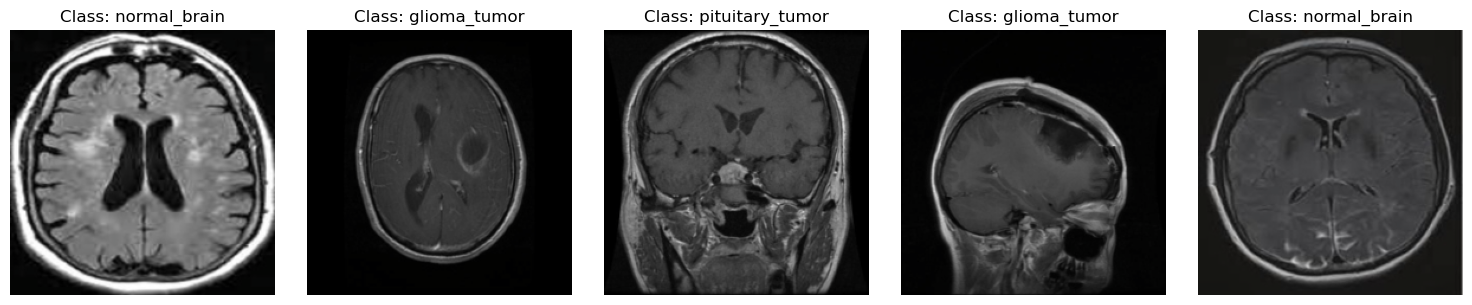


✅ Step 1 Complete! Dataset loaded successfully.


In [9]:

# Step 2: Import libraries
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models
import torchvision.models as tv_models
from sklearn.metrics import confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

# Step 3: Define dataset path
DATASET_PATH = r"C:\Users\janki\Downloads\BTMRI\BTMRI"

# Step 4: Check dataset structure
print("Checking dataset structure...")
print("Dataset path:", DATASET_PATH)
print("\nContents:", os.listdir(DATASET_PATH))

# Step 5: Explore class distribution
classes = []
for folder in os.listdir(DATASET_PATH):
    folder_path = os.path.join(DATASET_PATH, folder)
    if os.path.isdir(folder_path):
        class_count = len([f for f in os.listdir(folder_path) if f.endswith(('.jpg', '.png', '.jpeg'))])
        classes.append((folder, class_count))
        print(f"Class: {folder}, Images: {class_count}")

# Step 6: Define image preprocessing
image_size = 224  # ViT and Vision MAMBA input size

transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Step 7: Create custom dataset class
class BrainTumorDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.images = []
        self.labels = []
        self.class_names = []
        
        # Get class names
        for class_idx, class_name in enumerate(sorted(os.listdir(root_dir))):
            class_path = os.path.join(root_dir, class_name)
            if os.path.isdir(class_path):
                self.class_names.append(class_name)
                for img_name in os.listdir(class_path):
                    if img_name.endswith(('.jpg', '.png', '.jpeg')):
                        self.images.append(os.path.join(class_path, img_name))
                        self.labels.append(class_idx)
        
        print(f"Loaded {len(self.images)} images from {len(self.class_names)} classes")
        print(f"Classes: {self.class_names}")
    
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        img_path = self.images[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

# Step 8: Load the dataset
dataset = BrainTumorDataset(DATASET_PATH, transform=transform)

# Step 9: Split into train, validation, test sets
train_size = int(0.7 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(dataset, [train_size, val_size, test_size])

print(f"\nSplit sizes:")
print(f"Training: {len(train_dataset)} images")
print(f"Validation: {len(val_dataset)} images")
print(f"Test: {len(test_dataset)} images")

# Step 10: Create data loaders
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

# Step 11: Display sample images
def show_sample_images(dataset, num_images=5):
    fig, axes = plt.subplots(1, num_images, figsize=(15, 3))
    for i in range(num_images):
        img, label = dataset[i]
        img = img.permute(1, 2, 0).numpy()
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img = np.clip(img, 0, 1)
        axes[i].imshow(img)
        axes[i].set_title(f'Class: {dataset.dataset.class_names[label]}')
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

print("\nSample images from training set:")
show_sample_images(train_dataset)

print("\n✅ Step 1 Complete! Dataset loaded successfully.")

In [10]:
# Step 2: Vision MAMMA Model Implementation (CORRECTED)



# Simplified Mamba Block for CPU/Windows compatibility
class SimplifiedMambaBlock(nn.Module):
    """
    Simplified Mamba-like block for sequence processing
    This is a lightweight alternative to full Mamba for compatibility
    """
    def __init__(self, dim, d_state=16, expand=2):
        super().__init__()
        self.dim = dim
        self.d_state = d_state
        self.expand = expand
        self.inner_dim = int(dim * expand)
        
        # Projections
        self.in_proj = nn.Linear(dim, self.inner_dim * 2)
        self.out_proj = nn.Linear(self.inner_dim, dim)
        
        # SSM parameters (simplified)
        self.ssm = nn.Sequential(
            nn.Linear(self.inner_dim, d_state),
            nn.SiLU(),
            nn.Linear(d_state, self.inner_dim)
        )
        
        # Selective scan simulation (simplified)
        self.selective_scan = nn.Sequential(
            nn.Linear(self.inner_dim, self.inner_dim),
            nn.SiLU()
        )
        
        self.norm = nn.LayerNorm(dim)
        
    def forward(self, x):
        # x shape: (B, L, D)
        residual = x
        x = self.norm(x)
        
        # Input projection
        x_proj = self.in_proj(x)
        x_proj = x_proj.chunk(2, dim=-1)
        x1, x2 = x_proj[0], x_proj[1]
        
        # SSM processing
        x1 = self.ssm(x1)
        
        # Selective scan
        x2 = self.selective_scan(x2)
        
        # Combine
        x = x1 * x2
        x = self.out_proj(x)
        
        return x + residual

class VisionMAMMA(nn.Module):
    """
    Vision MAMMA Model for Brain Tumor Classification
    Combines CNN features with Mamba blocks for sequential processing
    """
    def __init__(self, num_classes=4, img_size=224, patch_size=16, dim=512, depth=6):
        super().__init__()
        
        # Patch embedding
        self.patch_size = patch_size
        self.img_size = img_size
        self.num_patches = (img_size // patch_size) ** 2
        self.dim = dim
        
        # CNN backbone for feature extraction
        self.cnn_backbone = tv_models.resnet34(pretrained=True)
        self.cnn_backbone = nn.Sequential(*list(self.cnn_backbone.children())[:-2])
        
        # Feature adapter
        self.feature_adapter = nn.Sequential(
            nn.AdaptiveAvgPool2d((img_size // 4, img_size // 4)),
            nn.Conv2d(512, dim, kernel_size=1),
            nn.BatchNorm2d(dim),
            nn.GELU()
        )
        
        # Position embedding
        num_patches = (img_size // 4) ** 2
        self.pos_embedding = nn.Parameter(torch.randn(1, num_patches, dim))
        
        # Mamba blocks
        self.mamba_blocks = nn.ModuleList([
            SimplifiedMambaBlock(dim, d_state=32, expand=2)
            for _ in range(depth)
        ])
        
        # Classification head
        self.norm = nn.LayerNorm(dim)
        self.classifier = nn.Sequential(
            nn.Linear(dim, dim // 2),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(dim // 2, num_classes)
        )
        
        # Initialize weights
        self._init_weights()
    
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.LayerNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
    
    def forward(self, x):
        # CNN feature extraction
        features = self.cnn_backbone(x)
        
        # Adapt features
        features = self.feature_adapter(features)
        
        # Convert to sequence
        B, C, H, W = features.shape
        features = features.flatten(2).transpose(1, 2)
        
        # Add position embedding
        features = features + self.pos_embedding[:, :features.shape[1], :]
        
        # Pass through Mamba blocks
        for mamba_block in self.mamba_blocks:
            features = mamba_block(features)
        
        # Global pooling
        features = features.mean(dim=1)
        
        # Classification
        features = self.norm(features)
        output = self.classifier(features)
        
        return output

# Create a lighter version for faster training
class VisionMAMMALight(nn.Module):
    """
    Lightweight Vision MAMMA for faster training on CPU
    """
    def __init__(self, num_classes=4, img_size=224):
        super().__init__()
        
        # Use a smaller CNN backbone
        self.cnn_backbone = tv_models.resnet18(pretrained=True)
        
        # Remove the final classification layer
        self.feature_extractor = nn.Sequential(*list(self.cnn_backbone.children())[:-1])
        
        # Feature dimension after resnet18
        feature_dim = 512
        
        # Mamba-inspired blocks (simplified)
        self.mamba_blocks = nn.Sequential(
            nn.Linear(feature_dim, 256),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(256, 128),
            nn.GELU(),
            nn.Dropout(0.1),
        )
        
        # Classification head
        self.classifier = nn.Linear(128, num_classes)
        
    def forward(self, x):
        # Extract features
        features = self.feature_extractor(x)
        features = features.flatten(1)
        
        # Mamba blocks
        features = self.mamba_blocks(features)
        
        # Classification
        output = self.classifier(features)
        
        return output

# Initialize the model
num_classes = len(dataset.class_names)
print(f"Number of classes: {num_classes}")
print(f"Classes: {dataset.class_names}")

# Choose model version
use_lightweight = True  # Set to False for full Vision MAMMA (requires more memory)

if use_lightweight:
    model = VisionMAMMALight(num_classes=num_classes, img_size=image_size)
    print("Using Vision MAMMA Lightweight version")
else:
    model = VisionMAMMA(num_classes=num_classes, img_size=image_size)
    print("Using Full Vision MAMMA version")

# Move model to device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)
print(f"Model loaded on: {device}")

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Test forward pass
test_input = torch.randn(1, 3, image_size, image_size).to(device)
test_output = model(test_input)
print(f"Test output shape: {test_output.shape}")
print(f"Output per class: {test_output[0].detach().cpu().numpy()}")

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

print("\n✅ Step 2 Complete! Vision MAMMA model created successfully.")
print(f"Model has {total_params:,} parameters and ready for training.")

Number of classes: 4
Classes: ['glioma_tumor', 'meningioma_tumor', 'normal_brain', 'pituitary_tumor']
Using Vision MAMMA Lightweight version
Model loaded on: cpu
Total parameters: 11,854,252
Trainable parameters: 11,854,252
Test output shape: torch.Size([1, 4])
Output per class: [ 0.07941446  0.0750998  -0.0869766   0.02674799]

✅ Step 2 Complete! Vision MAMMA model created successfully.
Model has 11,854,252 parameters and ready for training.


In [11]:
# Step 3: Federated Learning Simulation for Brain Tumor Classification

import copy
from collections import OrderedDict
import random
from tqdm import tqdm
import time

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

set_seed(42)

In [12]:

# ============================================
# PART 1: FEDERATED LEARNING CLIENT CLASS
# ============================================

class FederatedClient:
    """Represents a client in federated learning"""
    
    def __init__(self, client_id, train_loader, val_loader, model, criterion, device):
        self.client_id = client_id
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.model = copy.deepcopy(model)
        self.criterion = criterion
        self.device = device
        self.model.to(device)
        
    def train_local(self, epochs=5, lr=0.001):
        """Train model on local data"""
        self.model.train()
        optimizer = optim.Adam(self.model.parameters(), lr=lr)
        
        total_loss = 0
        correct = 0
        total = 0
        
        for epoch in range(epochs):
            running_loss = 0.0
            for batch_idx, (images, labels) in enumerate(self.train_loader):
                images, labels = images.to(self.device), labels.to(self.device)
                
                # Forward pass
                optimizer.zero_grad()
                outputs = self.model(images)
                loss = self.criterion(outputs, labels)
                
                # Backward pass
                loss.backward()
                optimizer.step()
                
                running_loss += loss.item()
                
                # Calculate accuracy
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()
                total_loss += loss.item()
        
        avg_loss = total_loss / len(self.train_loader)
        accuracy = 100. * correct / total if total > 0 else 0
        
        return avg_loss, accuracy
    
    def evaluate(self):
        """Evaluate model on validation data"""
        self.model.eval()
        total_loss = 0
        correct = 0
        total = 0
        
        with torch.no_grad():
            for images, labels in self.val_loader:
                images, labels = images.to(self.device), labels.to(self.device)
                outputs = self.model(images)
                loss = self.criterion(outputs, labels)
                
                total_loss += loss.item()
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()
        
        avg_loss = total_loss / len(self.val_loader)
        accuracy = 100. * correct / total if total > 0 else 0
        
        return avg_loss, accuracy
    
    def get_weights(self):
        """Get model weights"""
        return self.model.state_dict()
    
    def set_weights(self, weights):
        """Set model weights"""
        self.model.load_state_dict(weights)

In [13]:

# ============================================
# PART 2: FEDERATED LEARNING SERVER
# ============================================

class FederatedServer:
    """Central server for federated learning"""
    
    def __init__(self, global_model, test_loader, criterion, device):
        self.global_model = global_model
        self.test_loader = test_loader
        self.criterion = criterion
        self.device = device
        self.global_model.to(device)
        self.client_weights = []
        
    def aggregate_weights(self, client_weights, method='fedavg'):
        """
        Aggregate client weights using different strategies
        Methods: 'fedavg', 'median', 'trimmed_mean'
        """
        if method == 'fedavg':
            # Federated Averaging
            avg_weights = OrderedDict()
            for key in client_weights[0].keys():
                avg_weights[key] = torch.stack([w[key].float() for w in client_weights]).mean(dim=0)
            return avg_weights
        
        elif method == 'median':
            # Median aggregation (robust to outliers)
            avg_weights = OrderedDict()
            for key in client_weights[0].keys():
                avg_weights[key] = torch.stack([w[key].float() for w in client_weights]).median(dim=0)[0]
            return avg_weights
        
        elif method == 'trimmed_mean':
            # Trimmed mean (remove extreme values)
            avg_weights = OrderedDict()
            trim_ratio = 0.2  # Remove 20% of extreme values
            for key in client_weights[0].keys():
                stacked = torch.stack([w[key].float() for w in client_weights])
                k = int(trim_ratio * len(client_weights))
                if k > 0:
                    stacked = torch.sort(stacked, dim=0)[0][k:-k]
                avg_weights[key] = stacked.mean(dim=0)
            return avg_weights
        
        return client_weights[0]
    
    def federated_round(self, clients, round_num, epochs_per_round=3, aggregation='fedavg'):
        """Execute one round of federated learning"""
        
        print(f"\n--- Federated Round {round_num + 1} ---")
        
        # Store client results
        client_results = []
        
        # Train each client locally
        for client in clients:
            print(f"Training Client {client.client_id}...", end=" ")
            train_loss, train_acc = client.train_local(epochs=epochs_per_round)
            val_loss, val_acc = client.evaluate()
            client_results.append({
                'client_id': client.client_id,
                'train_loss': train_loss,
                'train_acc': train_acc,
                'val_loss': val_loss,
                'val_acc': val_acc
            })
            print(f"Train Acc: {train_acc:.2f}%, Val Acc: {val_acc:.2f}%")
            
            # Get client weights
            self.client_weights.append(client.get_weights())
        
        # Aggregate weights
        print(f"Aggregating {len(clients)} clients using {aggregation}...")
        global_weights = self.aggregate_weights(self.client_weights, method=aggregation)
        
        # Update global model
        self.global_model.load_state_dict(global_weights)
        
        # Update all clients with new global weights
        for client in clients:
            client.set_weights(global_weights)
        
        # Clear stored weights
        self.client_weights = []
        
        # Evaluate global model
        global_val_loss, global_val_acc = self.evaluate_global()
        
        return {
            'round': round_num + 1,
            'client_results': client_results,
            'global_val_loss': global_val_loss,
            'global_val_acc': global_val_acc
        }
    
    def evaluate_global(self):
        """Evaluate global model on validation data"""
        self.global_model.eval()
        total_loss = 0
        correct = 0
        total = 0
        
        with torch.no_grad():
            for images, labels in self.test_loader:
                images, labels = images.to(self.device), labels.to(self.device)
                outputs = self.global_model(images)
                loss = self.criterion(outputs, labels)
                
                total_loss += loss.item()
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()
        
        avg_loss = total_loss / len(self.test_loader)
        accuracy = 100. * correct / total if total > 0 else 0
        
        return avg_loss, accuracy

In [14]:

# ============================================
# PART 3: CREATE FEDERATED CLIENTS (DATA PARTITIONING)
# ============================================

def create_federated_clients(train_dataset, val_dataset, num_clients=5, 
                             samples_per_client=100, batch_size=16):
    """
    Create non-IID data distribution for federated learning
    """
    
    # Get class labels for all samples
    all_labels = []
    for idx in range(len(train_dataset)):
        _, label = train_dataset[idx]
        all_labels.append(label)
    
    all_labels = np.array(all_labels)
    
    # Create client datasets (non-IID distribution)
    client_datasets = []
    
    for client_id in range(num_clients):
        # Each client gets a skewed distribution of classes
        # Simulate real-world scenario where different hospitals have different data distributions
        
        # Determine class distribution for this client
        if client_id == 0:
            # Client 0: More glioma tumors
            class_weights = [0.4, 0.2, 0.2, 0.2]
        elif client_id == 1:
            # Client 1: More meningioma tumors
            class_weights = [0.2, 0.4, 0.2, 0.2]
        elif client_id == 2:
            # Client 2: More normal brains
            class_weights = [0.2, 0.2, 0.4, 0.2]
        elif client_id == 3:
            # Client 3: More pituitary tumors
            class_weights = [0.2, 0.2, 0.2, 0.4]
        else:
            # Client 4: Balanced distribution
            class_weights = [0.25, 0.25, 0.25, 0.25]
        
        # Sample indices for this client
        client_indices = []
        for class_idx in range(len(class_weights)):
            class_indices = np.where(all_labels == class_idx)[0]
            num_samples = int(samples_per_client * class_weights[class_idx])
            num_samples = min(num_samples, len(class_indices))
            if num_samples > 0:
                sampled = np.random.choice(class_indices, num_samples, replace=False)
                client_indices.extend(sampled)
        
        # Create subset for this client
        client_train = torch.utils.data.Subset(train_dataset, client_indices)
        
        # Each client also gets validation data
        val_indices = np.random.choice(len(val_dataset), 
                                      min(50, len(val_dataset)), 
                                      replace=False)
        client_val = torch.utils.data.Subset(val_dataset, val_indices)
        
        # Create data loaders
        client_train_loader = DataLoader(client_train, batch_size=batch_size, shuffle=True)
        client_val_loader = DataLoader(client_val, batch_size=batch_size, shuffle=False)
        
        client_datasets.append((client_train_loader, client_val_loader))
        
        # Print client distribution
        client_labels = [all_labels[idx] for idx in client_indices]
        print(f"Client {client_id}: Distribution - "
              f"Class0: {client_labels.count(0)}, "
              f"Class1: {client_labels.count(1)}, "
              f"Class2: {client_labels.count(2)}, "
              f"Class3: {client_labels.count(3)}")
    
    return client_datasets


FEDERATED LEARNING SIMULATION FOR BRAIN TUMOR CLASSIFICATION

Creating 5 federated clients...
Client 0: Distribution - Class0: 60, Class1: 30, Class2: 30, Class3: 30
Client 1: Distribution - Class0: 30, Class1: 60, Class2: 30, Class3: 30
Client 2: Distribution - Class0: 30, Class1: 30, Class2: 60, Class3: 30
Client 3: Distribution - Class0: 30, Class1: 30, Class2: 30, Class3: 60
Client 4: Distribution - Class0: 37, Class1: 37, Class2: 37, Class3: 37

Starting Federated Learning with:
  - Number of clients: 5
  - Number of rounds: 5
  - Local epochs per round: 3
  - Aggregation method: fedavg

--- Federated Round 1 ---
Training Client 0... Train Acc: 66.67%, Val Acc: 74.00%
Training Client 1... Train Acc: 68.44%, Val Acc: 46.00%
Training Client 2... Train Acc: 71.78%, Val Acc: 72.00%
Training Client 3... Train Acc: 65.78%, Val Acc: 62.00%
Training Client 4... Train Acc: 78.15%, Val Acc: 54.00%
Aggregating 5 clients using fedavg...
Round 1 Complete - Global Val Acc: 24.13%

--- Federate

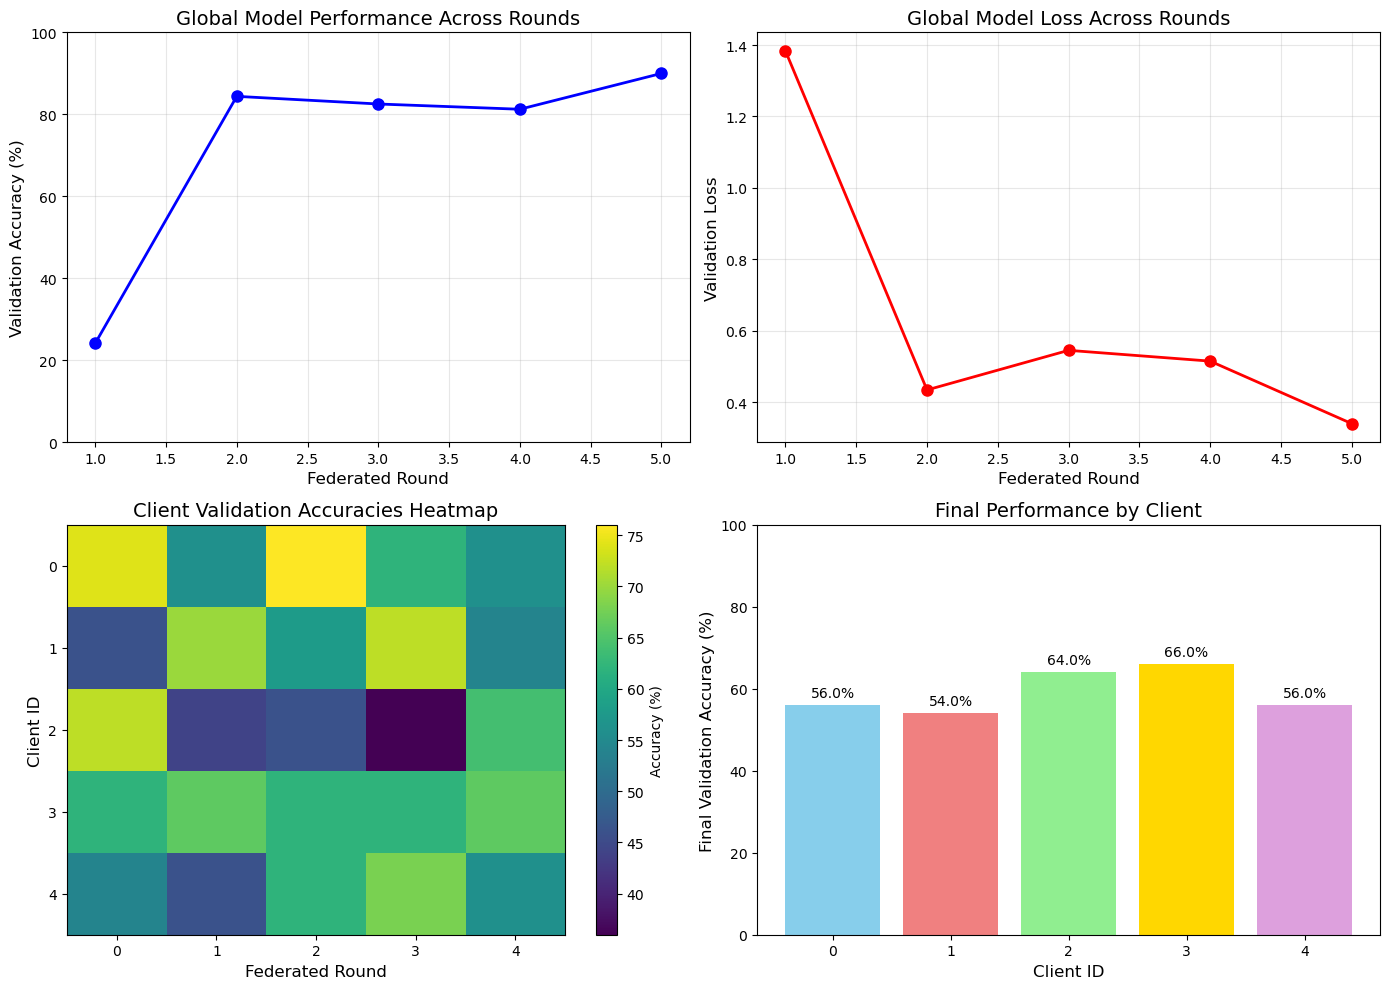


FINAL EVALUATION ON TEST SET

Final Global Model Test Results:
  Test Loss: 0.3401
  Test Accuracy: 89.98%
  Total Test Samples: 858

Classification Report:
                  precision    recall  f1-score   support

    glioma_tumor       0.93      0.97      0.95       198
meningioma_tumor       0.88      0.76      0.81       207
    normal_brain       0.94      0.94      0.94       230
 pituitary_tumor       0.86      0.93      0.89       223

        accuracy                           0.90       858
       macro avg       0.90      0.90      0.90       858
    weighted avg       0.90      0.90      0.90       858



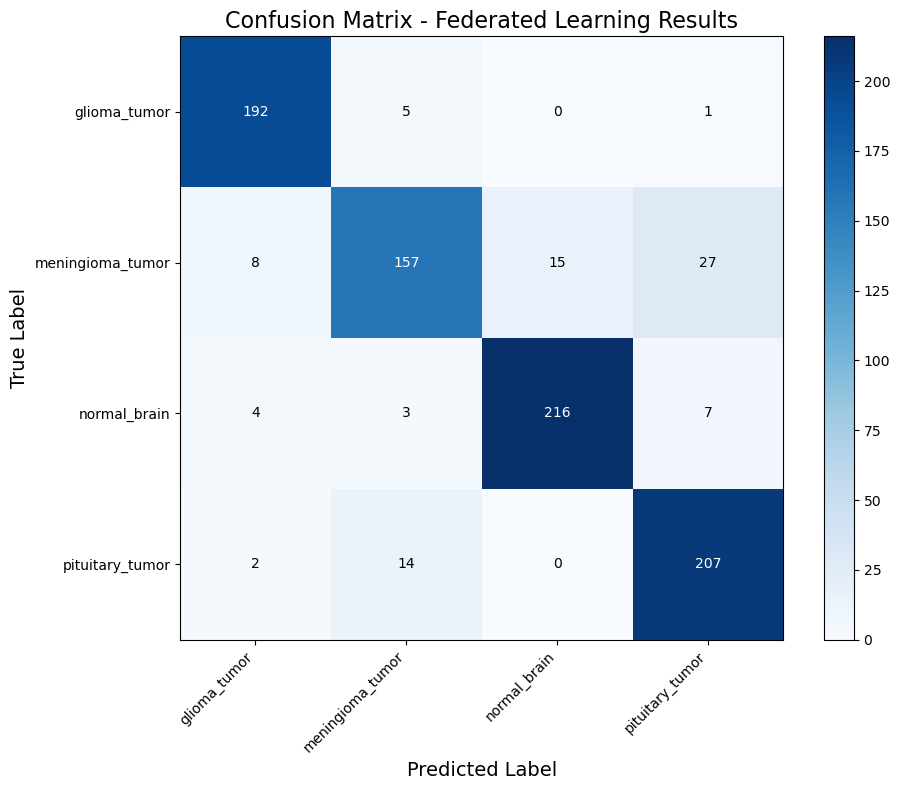


✅ Model saved as 'federated_brain_tumor_model.pth'

✅ Step 3 Complete! Federated Learning training finished successfully.


In [15]:
# ============================================
# PART 4: TRAINING WITH FEDERATED LEARNING
# ============================================

print("\n" + "="*60)
print("FEDERATED LEARNING SIMULATION FOR BRAIN TUMOR CLASSIFICATION")
print("="*60)

# Create federated clients
num_clients = 5
samples_per_client = 150  # Each client gets 150 samples

print(f"\nCreating {num_clients} federated clients...")
client_datasets = create_federated_clients(
    train_dataset, 
    val_dataset, 
    num_clients=num_clients,
    samples_per_client=samples_per_client,
    batch_size=16
)

# Create client objects
clients = []
for i, (train_loader, val_loader) in enumerate(client_datasets):
    # Create a fresh copy of the model for each client
    client_model = VisionMAMMALight(num_classes=num_classes, img_size=image_size)
    client = FederatedClient(
        client_id=i,
        train_loader=train_loader,
        val_loader=val_loader,
        model=client_model,
        criterion=criterion,
        device=device
    )
    clients.append(client)

# Initialize server with global model
global_model = VisionMAMMALight(num_classes=num_classes, img_size=image_size)
server = FederatedServer(
    global_model=global_model,
    test_loader=test_loader,
    criterion=criterion,
    device=device
)

# ============================================
# PART 5: RUN FEDERATED LEARNING ROUNDS
# ============================================

num_rounds = 5  # Number of federated rounds
epochs_per_round = 3  # Local training epochs per round
aggregation_method = 'fedavg'  # fedavg, median, or trimmed_mean

print(f"\nStarting Federated Learning with:")
print(f"  - Number of clients: {num_clients}")
print(f"  - Number of rounds: {num_rounds}")
print(f"  - Local epochs per round: {epochs_per_round}")
print(f"  - Aggregation method: {aggregation_method}")

# Store training history
history = {
    'rounds': [],
    'global_val_acc': [],
    'global_val_loss': [],
    'client_accuracies': []
}

# Training loop
start_time = time.time()

for round_idx in range(num_rounds):
    # Perform one federated round
    round_result = server.federated_round(
        clients, 
        round_idx, 
        epochs_per_round=epochs_per_round,
        aggregation=aggregation_method
    )
    
    # Store history
    history['rounds'].append(round_result['round'])
    history['global_val_acc'].append(round_result['global_val_acc'])
    history['global_val_loss'].append(round_result['global_val_loss'])
    
    # Store client accuracies
    client_accs = [r['val_acc'] for r in round_result['client_results']]
    history['client_accuracies'].append(client_accs)
    
    print(f"Round {round_result['round']} Complete - Global Val Acc: {round_result['global_val_acc']:.2f}%")

training_time = time.time() - start_time
print(f"\n✅ Federated Learning completed in {training_time:.2f} seconds!")

# ============================================
# PART 6: VISUALIZE RESULTS
# ============================================

# Plot training progress
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Global Validation Accuracy
axes[0, 0].plot(history['rounds'], history['global_val_acc'], 'b-o', linewidth=2, markersize=8)
axes[0, 0].set_xlabel('Federated Round', fontsize=12)
axes[0, 0].set_ylabel('Validation Accuracy (%)', fontsize=12)
axes[0, 0].set_title('Global Model Performance Across Rounds', fontsize=14)
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_ylim([0, 100])

# Plot 2: Global Validation Loss
axes[0, 1].plot(history['rounds'], history['global_val_loss'], 'r-o', linewidth=2, markersize=8)
axes[0, 1].set_xlabel('Federated Round', fontsize=12)
axes[0, 1].set_ylabel('Validation Loss', fontsize=12)
axes[0, 1].set_title('Global Model Loss Across Rounds', fontsize=14)
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Client Accuracies Heatmap
client_acc_matrix = np.array(history['client_accuracies']).T
im = axes[1, 0].imshow(client_acc_matrix, cmap='viridis', aspect='auto', interpolation='nearest')
axes[1, 0].set_xlabel('Federated Round', fontsize=12)
axes[1, 0].set_ylabel('Client ID', fontsize=12)
axes[1, 0].set_title('Client Validation Accuracies Heatmap', fontsize=14)
plt.colorbar(im, ax=axes[1, 0], label='Accuracy (%)')

# Plot 4: Client Performance Box Plot
client_final_accs = [history['client_accuracies'][-1][i] for i in range(num_clients)]
axes[1, 1].bar(range(num_clients), client_final_accs, color=['skyblue', 'lightcoral', 'lightgreen', 'gold', 'plum'])
axes[1, 1].set_xlabel('Client ID', fontsize=12)
axes[1, 1].set_ylabel('Final Validation Accuracy (%)', fontsize=12)
axes[1, 1].set_title('Final Performance by Client', fontsize=14)
axes[1, 1].set_xticks(range(num_clients))
axes[1, 1].set_ylim([0, 100])
for i, acc in enumerate(client_final_accs):
    axes[1, 1].text(i, acc + 2, f'{acc:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

# ============================================
# PART 7: FINAL EVALUATION ON TEST SET
# ============================================

print("\n" + "="*60)
print("FINAL EVALUATION ON TEST SET")
print("="*60)

# Evaluate global model on test set
server.global_model.eval()
all_predictions = []
all_labels_list = []

test_loss = 0
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = server.global_model(images)
        loss = criterion(outputs, labels)
        
        test_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
        all_predictions.extend(predicted.cpu().numpy())
        all_labels_list.extend(labels.cpu().numpy())

test_accuracy = 100. * correct / total
test_loss = test_loss / len(test_loader)

print(f"\nFinal Global Model Test Results:")
print(f"  Test Loss: {test_loss:.4f}")
print(f"  Test Accuracy: {test_accuracy:.2f}%")
print(f"  Total Test Samples: {total}")

# Classification Report
print("\nClassification Report:")
print(classification_report(all_labels_list, all_predictions, 
                           target_names=dataset.class_names))

# Confusion Matrix
cm = confusion_matrix(all_labels_list, all_predictions)

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Confusion Matrix - Federated Learning Results', fontsize=16)
plt.colorbar()
tick_marks = np.arange(len(dataset.class_names))
plt.xticks(tick_marks, dataset.class_names, rotation=45, ha='right')
plt.yticks(tick_marks, dataset.class_names)

# Add text annotations
thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black")

plt.ylabel('True Label', fontsize=14)
plt.xlabel('Predicted Label', fontsize=14)
plt.tight_layout()
plt.show()

# Save the global model
torch.save(server.global_model.state_dict(), 'federated_brain_tumor_model.pth')
print("\n✅ Model saved as 'federated_brain_tumor_model.pth'")

print("\n✅ Step 3 Complete! Federated Learning training finished successfully.")



In [16]:
import sys
print(sys.executable)

C:\Users\janki\anaconda3\python.exe
